# Vehicale Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/home/jawad/my_jupyter_env/Data_Science_Projects/Urban-Road-Safety-Near-Miss-Analysis/urban_near_miss_dataset_12000.csv")

In [3]:
df.head()

,Record_ID,City,Day_of_Week,Hour,Weather,Traffic_Level,Vehicle_Type,Road_Type,Speed_Limit_kmh,Average_Speed_kmh,Pedestrian_Count,Visibility_Percent,Near_Miss_Score,Incident
0,1,Peshawar,Thursday,6,Cloudy,Medium,Motorcycle,Main Road,60,51.7,11,82.3,40.2,0
1,2,Karachi,Friday,19,Clear,Medium,Bus,Residential,50,51.8,10,91.1,31.6,0
2,3,Rawalpindi,Friday,14,Clear,Medium,Rickshaw,Residential,50,74.7,11,82.2,44.8,0
3,4,Peshawar,Sunday,10,Rain,High,Car,Main Road,60,39.4,7,74.0,35.6,0
4,5,Rawalpindi,Saturday,7,Rain,Severe,Rickshaw,Highway,100,62.5,8,97.3,57.1,1


In [4]:
# vehicale type 
vehicale_type = ['Motorcycle', 'Bus','Rickshaw', 'Car']
df["Vehicle_Type"] = pd.Categorical(df["Vehicle_Type"],categories= vehicale_type,ordered = True)

countt_vehicle = df["Vehicle_Type"].value_counts().reindex(vehicale_type)
print(countt_vehicle)
print("__"*30)


# which vehicle type occure most often ?
most_occure_vehicle_type = countt_vehicle.idxmax()
print("\nmost occuring vehicle type : ",most_occure_vehicle_type)

# which vehicle type has the most incident ?
most_incident_vehicle = df.groupby("Vehicle_Type")["Incident"].idxmax()
print("most incident vehicle type : ",most_occure_vehicle_type)

# which vehicle type has the most highest average near miss score ?
vehicle_high_Near_miss_score = df.groupby("Vehicle_Type")["Near_Miss_Score"].mean().idxmax()
print("vehicle type highest Average Near Miss Score : \n",vehicle_high_Near_miss_score)
print("__"*30)

# calculate incident rate for each vehicle type ?
total = df.groupby("Vehicle_Type").size()
incidents = df.groupby("Vehicle_Type")["Incident"].sum()
incident_rate = (incidents / total) * 100
print("\nIncident rate each vehicle type : ",incident_rate)



Vehicle_Type
Motorcycle    4111
Bus            938
Rickshaw      2134
Car           3615
Name: count, dtype: int64
____________________________________________________________

most occuring vehicle type :  Motorcycle
most incident vehicle type :  Motorcycle
vehicle type highest Average Near Miss Score : 
 Motorcycle
____________________________________________________________

Incident rate each vehicle type :  Vehicle_Type
Motorcycle    23.060083
Bus           12.579957
Rickshaw      14.339269
Car           13.997234
dtype: float64


/tmp/ipykernel_22053/133102198.py:3: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  df["Vehicle_Type"] = pd.Categorical(df["Vehicle_Type"],categories= vehicale_type,ordered = True)


# Vehicle Type vs Incident Count

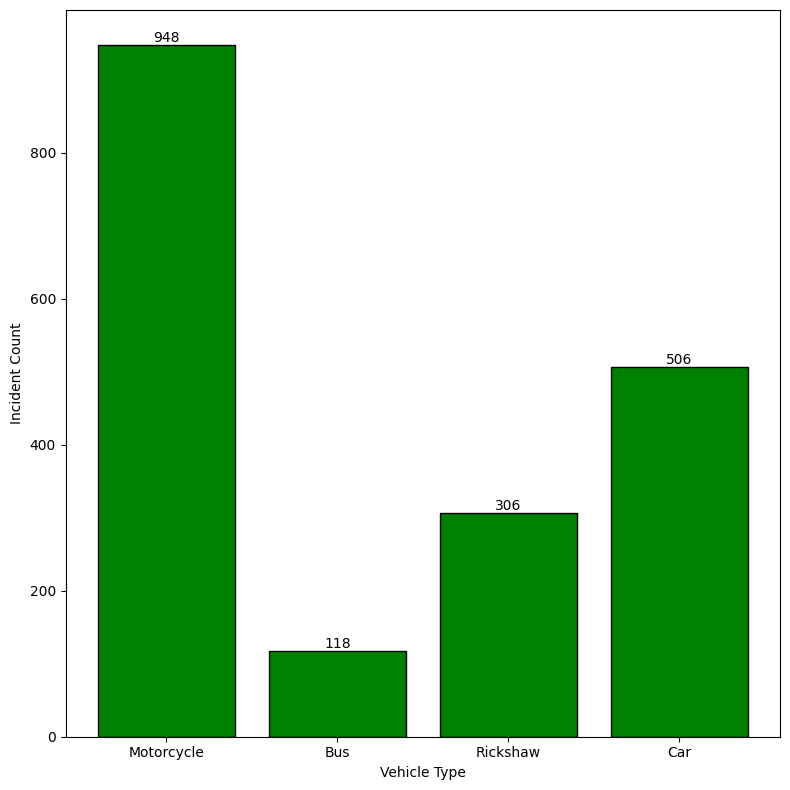

In [5]:
count_incident_veh_type = df.groupby("Vehicle_Type")["Incident"].sum()
plt.figure(figsize=(8,8))
bar = plt.bar(count_incident_veh_type.index,count_incident_veh_type.values,color="Green",edgecolor="Black")
plt.bar_label(bar)
plt.xlabel("Vehicle Type")
plt.ylabel("Incident Count")
plt.tight_layout()
plt.savefig("vehicale_type_VS_incident.png",dpi=300,bbox_inches = "tight")
plt.show()